# 01 - Data exploration and leakage-free re-split

Dataset: [detection-player v4](https://universe.roboflow.com/fsdm-olss1/detection-player/dataset/4) by fsdm-olss1 (Roboflow Universe), licensed CC BY 4.0.
Classes: ball, goalkeeper, player, referee.

The original train/valid/test split is random at frame level, so near-identical frames end up in different splits.
This notebook measures that leakage and builds a new split grouped by visual similarity.

In [1]:
!pip install -q roboflow imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 29.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 1.7 MB/s eta 0:00:00


## 1. Download

In [2]:
from getpass import getpass
from roboflow import Roboflow

rf = Roboflow(api_key=getpass("Roboflow API key: "))
project = rf.workspace("fsdm-olss1").project("detection-player")
project.version(4).download("yolov8", location="/content/data/raw")

Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/data/raw in yolov8:: 100%|██████████| 4670/4670 [00:01<00:00, 3168.02it/s]


## 2. Original split

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd

root = Path("/content/data/raw")
names = ["ball", "goalkeeper", "player", "referee"]
splits = ["train", "valid", "test"]

items = [(sp, p.name) for sp in splits for p in sorted((root / sp / "images").glob("*.jpg"))]


def class_counts(entries):
    rows = []
    for split, sp, nm in entries:
        label_file = root / sp / "labels" / (Path(nm).stem + ".txt")
        for line in label_file.read_text().splitlines():
            rows.append({"split": split, "class": names[int(line.split()[0])]})
    out = pd.DataFrame(rows).groupby(["split", "class"]).size().unstack(fill_value=0)
    out["images"] = pd.Series([e[0] for e in entries]).value_counts()
    return out.loc[splits]


class_counts([(sp, sp, nm) for sp, nm in items])

class,ball,goalkeeper,player,referee,images
split,,,,,
train,1479,1354,18461,2212,1844
valid,246,229,2921,351,310
test,140,125,1799,225,175


## 3. Perceptual hashes (original and mirrored)

In [4]:
import imagehash
from PIL import Image, ImageOps


def phash_bits(img):
    return imagehash.phash(img).hash.flatten()


bits, flip_bits = [], []
for sp, nm in items:
    img = Image.open(root / sp / "images" / nm)
    bits.append(phash_bits(img))
    flip_bits.append(phash_bits(ImageOps.mirror(img)))

bits = np.array(bits, dtype=np.float32)
flip_bits = np.array(flip_bits, dtype=np.float32)


def hamming(a, b):
    return a.sum(1)[:, None] + b.sum(1)[None, :] - 2 * a @ b.T

## 4. Leakage in the original split

In [5]:
THRESHOLD = 6

split_of = np.array([sp for sp, _ in items])
is_train = split_of == "train"

for sp in ["valid", "test"]:
    mask = split_of == sp
    d = np.minimum(hamming(bits[mask], bits[is_train]), hamming(bits[mask], flip_bits[is_train]))
    print(f"{sp}: {(d <= THRESHOLD).any(1).sum()} / {mask.sum()} images have a near-duplicate in train")

valid: 289 / 310 images have a near-duplicate in train
test: 165 / 175 images have a near-duplicate in train


## 5. Similarity groups

In [6]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

D = np.minimum(hamming(bits, bits), hamming(bits, flip_bits))
n_groups, labels = connected_components(csr_matrix(D <= THRESHOLD), directed=False)
sizes = np.bincount(labels)

print("images:", len(items), "| groups:", n_groups)
print("largest groups:", np.sort(sizes)[::-1][:10])
print("single-image groups:", (sizes == 1).sum())

images: 2329 | groups: 223
largest groups: [556 227 158 126 111 111  90  90  86  63]
single-image groups: 113


## 6. Group-level split (70 / 15 / 15)

In [7]:
targets = {"train": 0.70, "valid": 0.15, "test": 0.15}
total = len(items)
assigned = dict.fromkeys(targets, 0)
group_split = {}

for g in np.argsort(-sizes, kind="stable"):
    pick = max(targets, key=lambda k: targets[k] * total - assigned[k])
    group_split[g] = pick
    assigned[pick] += sizes[g]

new_split = [group_split[g] for g in labels]
class_counts([(new, sp, nm) for new, (sp, nm) in zip(new_split, items)])

class,ball,goalkeeper,player,referee,images
split,,,,,
train,1424,1224,15649,2137,1630
valid,165,247,3780,347,350
test,276,237,3752,304,349


## 7. Remove augmented copies from valid and test

In [8]:
source = lambda nm: nm.split(".rf.")[0]

keep, seen = [], set()
for i, ((sp, nm), new, g) in enumerate(zip(items, new_split, labels)):
    key = (new, g, source(nm))
    if new != "train" and key in seen:
        continue
    seen.add(key)
    keep.append(i)

final = [(new_split[i], *items[i]) for i in keep]
class_counts(final)

class,ball,goalkeeper,player,referee,images
split,,,,,
train,1424,1224,15649,2137,1630
valid,140,192,2836,271,275
test,231,221,3115,237,298


## 8. Build the final dataset

In [9]:
import shutil

import yaml

out = Path("/content/data/football")
shutil.rmtree(out, ignore_errors=True)

for new, sp, nm in final:
    stem = Path(nm).stem
    for kind, fname in [("images", nm), ("labels", stem + ".txt")]:
        dst = out / new / kind
        dst.mkdir(parents=True, exist_ok=True)
        shutil.copy(root / sp / kind / fname, dst / fname)

cfg = {
    "path": str(out),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": dict(enumerate(names)),
}
(out / "data.yaml").write_text(yaml.dump(cfg, sort_keys=False))

manifest = pd.DataFrame(final, columns=["split", "original_split", "file"])
manifest.to_csv(out / "split_manifest.csv", index=False)

for sp in splits:
    print(sp, len(list((out / sp / "images").glob("*.jpg"))), len(list((out / sp / "labels").glob("*.txt"))))

train 1630 1630
valid 275 275
test 298 298


## 9. Sample images

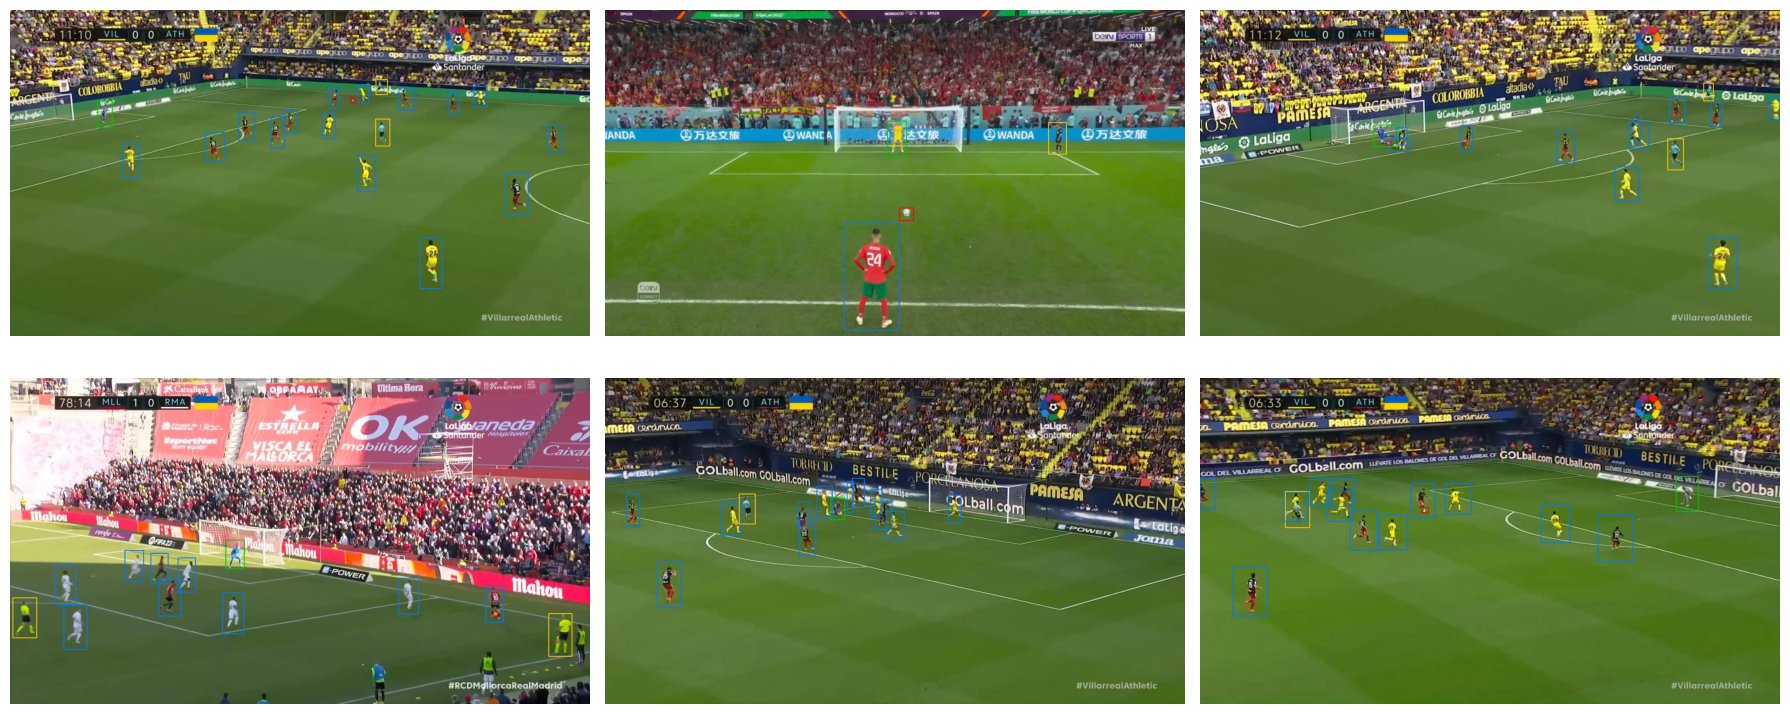

In [10]:
import random

import cv2
import matplotlib.pyplot as plt

colors = {0: (255, 0, 0), 1: (0, 200, 0), 2: (0, 120, 255), 3: (255, 200, 0)}
sample = random.Random(0).sample(sorted((out / "train" / "images").glob("*.jpg")), 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, p in zip(axes.ravel(), sample):
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for line in (out / "train" / "labels" / (p.stem + ".txt")).read_text().splitlines():
        c, x, y, bw, bh = (float(v) for v in line.split()[:5])
        x1, y1 = int((x - bw / 2) * w), int((y - bh / 2) * h)
        x2, y2 = int((x + bw / 2) * w), int((y + bh / 2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), colors[int(c)], 2)
    ax.imshow(img)
    ax.axis("off")
plt.tight_layout()

## 10. Save to Google Drive

In [11]:
from google.colab import drive

drive.mount("/content/drive")
drive_dir = Path("/content/drive/MyDrive/football-analytics")
drive_dir.mkdir(exist_ok=True)

archive = shutil.make_archive(str(drive_dir / "football_dataset_v1"), "zip", "/content/data", "football")
print(archive, round(Path(archive).stat().st_size / 1e6, 1), "MB")

Mounted at /content/drive
/content/drive/MyDrive/football-analytics/football_dataset_v1.zip 400.0 MB
